# 5.2 - Choosing a learning algorithm, second version: repairing the learning task

Notebook 5.1 took the eight learning algorithms of Damon Lee's *Build Your Own AI Investor* (2nd edition), with the
book's own settings, and chose among them the way an investor would have had to: each model trained only on years
already over, judged by how well it ranked companies, and chosen each January from the evidence available that day.
None of the eight ranked S&P 1500 companies better than chance, and no portfolio built on them beat the market by more
than luck allows.

That result can mean two things: there is nothing to learn from these data, or the models were asked the wrong
question in the wrong way. This notebook tests the second. It keeps everything 5.1 fixed - the eight algorithms, the
walk-forward training, the yardstick, the choice rule, the portfolio - and changes four things about the learning task,
each for a reason diagnosed in 5.1's results:

1. **The target**: each company's *percentile* among the index's members by its year-ahead return, instead of the
   return itself.
2. **The features**: each ratio as a percentile among the members on its date, instead of its level.
3. **The settings**: far less flexible models - shallow trees with large leaves, slow boosting, wide neighbourhoods -
   chosen from the research literature, not tuned on our results.
4. **The information**: eight features beyond the book's 18 accounting ratios - price trends, risk, size, share
   issuance, earnings surprises and growth.

The read this notebook needs: notebook 5.1 for what each algorithm does. Every new idea is explained here.

## What notebook 5.1 found, and why it pointed here

| | notebook 5.1 (the book's set-up) |
|---|---|
| Best mean rank IC, 2009-2023 | +0.003 (gradient-boosted trees and the decision tree; Newey-West t at most +0.5) |
| Worst mean rank IC | -0.028 (elastic net), with linear regression and extra trees at -0.027 |
| Portfolios, 2010-2024 | 12.6 % to 14.7 % a year, against SPTM's 13.7 % |
| Best deflated active Sharpe ratio | 28 % (k-nearest neighbours), against 95 % for evidence |

A diagnosis afterwards (on 7 November 2026, from 5.1's own predictions) found three problems with the learning task:

* **Extreme targets.** A company's year-ahead return ran from -77 % to +153 % between the 1st and 99th percentiles,
  and the largest was **+8,364 %**. Every model except SVR rests on squared errors $\sum_i (y_i - \hat y_i)^2$ or
  on averages (a tree's leaf predicts the average of its companies, a neighbourhood the average of its neighbours -
  the same thing locally). Squaring makes one company that returned 80 times its price count as much as thousands of
  ordinary ones, so the fit bends towards a few outliers instead of the typical company.
* **Learning the wrong thing.** Part of the variation in a raw return is the market's year: in 2009 almost everything
  rose. Elastic net put 76 % of the variation in its predictions into *which month* would be good, extra trees 50 %
  and linear regression 35 % - and those were the three with negative ICs. A portfolio that ranks companies against
  each other cannot use a forecast of the market.
* **Drifting features.** The median price-to-sales ratio rose from 1.15 in 2008 to 2.08 in 2024, and the median
  EV/EBIT from 11.1 to 15.6. A tree that learned in 2009 that "P/S below 1.5 is cheap" applies the same threshold in
  2024, when it picks out a much smaller and different group of companies.

A fourth reason was visible without a diagnosis: the book's 18 features are almost all accounting levels, and the
research literature finds that most of what predicts stock returns lies elsewhere (below).

## The four changes

### 1. Learn percentiles, not returns

For each decision date $t$, the $N_t$ index members are sorted by the return each went on to earn over the next year,
and each is given its percentile:
$$y_{i,t} = \frac{\operatorname{rank}_t\left(r_{i,t\to t+1y}\right)}{N_t} \in (0, 1].$$
The best company of the year scores 1, the median about 0.5, the worst close to 0 - whether the best returned +30 % or
+8,000 %. This target is *bounded*, so no company dominates the squared errors; and its average is the same
(about 0.5) on every date, so there is nothing to learn about which year was good. It is also exactly what the
yardstick measures: the rank IC compares the *order* of predictions with the *order* of returns, so the models are now
trained on the quantity they are judged by. (The rank IC is still computed against the raw returns; ranking them first
gives the same Spearman correlation.)

### 2. Percentile features

Each feature is replaced by its percentile among the date's members in the same way. "A P/S at the 20th percentile"
means "cheaper than 80 % of the index" in 2008 and in 2024 alike, while a P/S of 1.5 does not. Percentiles also remove
the need for the book's clipping and for the power transform: every feature is spread evenly between 0 and 1.
Missing values still take the training set's median (about 0.5: an unknown company is treated as average).

### 3. Settings for a weak signal

When the signal is weak - and in stock returns it is, an IC of 0.05 is good - a flexible model mostly learns noise.
*Regularisation* means limiting how closely a model can follow its training data. Gu, Kelly and Xiu (2020, *Review of
Financial Studies*), the largest study of machine learning on US stock returns, found that the models that worked were
heavily regularised: boosted trees of depth 1-2, forests of shallow trees, linear models with penalties chosen on
held-out years. The settings below follow that, and were written down before any result of this notebook was seen.

| Algorithm | Book (5.1) | Here | What the change does |
|---|---|---|---|
| Linear regression | power transform first | none needed | percentile features are already evenly spread |
| Elastic net | $\alpha$ = 1 fixed, L1 share $10^{-5}$ | $\alpha$ and L1 share (0.1, 0.5, 0.9, 1) chosen by 5-fold blocked cross-validation in each training window | the penalty's right size depends on the data, so it is chosen - but only on the training years |
| k-nearest neighbours | 40 neighbours | 500 | each prediction averages 500 similar company-dates, so one company's luck barely moves it |
| SVR | $C$ = 100, $\gamma$ = 0.1 | $C$ = 1, $\gamma$ = "scale" | a lower $C$ makes errors cheaper, so the curve is smoother; $\gamma$ = $1/(p\,\mathrm{Var}(x))$ fits the kernel's width to the data |
| Decision tree | depth 20 | depth 4, leaves of at least 500 | at most 16 groups of companies, each large enough to have an average worth trusting |
| Random forest | 100 trees, depth 10 | 300 trees, depth 6, a third of the features per split, leaves of 500 | shallower trees, made more different from each other, then averaged |
| Extra trees | 100 trees, depth 10 | as the random forest | as the random forest |
| Gradient-boosted trees | exact, 100 trees of depth 10, rate 0.1 | histogram-based, 300 trees of depth 2, rate 0.05, L2 penalty 1, leaves of 500 | each tree can capture only a pair of features at a time; many small, shrunken steps |

*Blocked cross-validation* (for the elastic net): the training window's company-dates, in date order, are cut into
five consecutive blocks; each candidate penalty is fitted on four and scored on the fifth, in turn, and the best
average wins. The blocks keep neighbouring dates together, so a model is scored on dates it has not seen. (Overlapping
year-ahead returns at the edge of a block still leak a little; that only affects which penalty is chosen, never the
year predicted, which lies outside the window altogether.)

*Leaves of at least 500*: a leaf is a final group of a tree, and its prediction is the average target of its training
companies. With 500 or more, the average is of many companies, not a lucky few. The first training window (January
2009) has about 11,000 company-dates, so even then a tree can have up to 22 leaves.

### 4. More information

| Feature | What it is | Why it might predict |
|---|---|---|
| `momentum_12_1` | return from 12 months to 1 month ago | winners keep winning for months (Jegadeesh and Titman, 1993) |
| `return_1m` | last month's return | last month's winners tend to give some back (Jegadeesh, 1990) |
| `volatility_1y` | annualised volatility of daily returns over a year | calmer shares have earned as much as volatile ones, or more (Ang et al., 2006) |
| `size` | market value | small companies behave differently from large ones (Banz, 1981) |
| `share_change` | log change in shares outstanding over the year | companies issuing shares underperform, those buying back outperform (Pontiff and Woodgate, 2008) |
| `earnings_surprise` | the latest quarter's standardised earnings surprise | prices drift after earnings news (Bernard and Thomas, 1989) |
| `eps_growth`, `sales_growth` | yearly growth of trailing earnings and sales per share | growth the price has not yet reflected |

Each is known on its date (no look-ahead) and, like the ratios, becomes a percentile among the members. The model now
has 26 features. In Gu, Kelly and Xiu's study the most useful predictors were price trends, liquidity and volatility -
the kind the book left out.

### The same toy data, version 2's settings

The made-up feature of notebook 5.1 - a wavy relation in fat-tailed noise - now with 20,000 points (version 2's
settings need many: a leaf of 500 and 500 neighbours are meaningless with 400). Compare with 5.1's panels: the
staircase of the depth-20 tree and the jumps of the depth-10 boosting are gone; every model now draws a smooth curve.

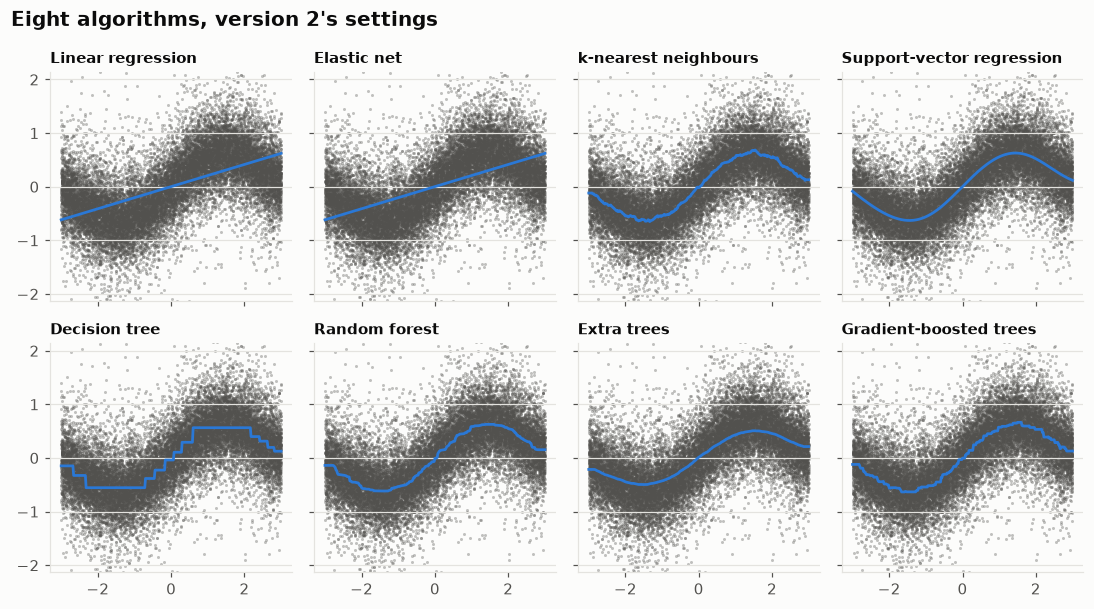

In [1]:
import warnings
from dataclasses import replace

import numpy as np
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research import ml
from equity_research.research import model_choice as mc
from equity_research.research import model_choice_v2 as v2
from equity_research.research.backtest import decile_returns
from equity_research.research.cache import ResearchCache
from equity_research.research.data import load_universe_data
from equity_research.research.indices import calendar_years, vendor_returns
from equity_research.research.registry import trial_count
from equity_research.research.runs import score_metrics
from equity_research.research.strategy import TRAIN_FROM, StrategyConfig, deflated_active

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
charts.style()
# eps and sales growth have no values before 2008, so the first training windows lack them; the imputer drops such a
# column for that fit (and says so for every fit) - expected, not a fault
warnings.filterwarnings("ignore", message="Skipping features without any observed values")
LABELS = {name: c.label for name, c in v2.CANDIDATES.items()} | {mc.FALLBACK: "Ensemble of all eight"}

x, y = mc.toy_data(20_000)
grid = np.linspace(-3, 3, 301)
fig = charts.fit_panels(
    x, y, mc.toy_fits(x, y, grid, v2.CANDIDATES), "Eight algorithms, version 2's settings", labels=LABELS
)

## Step 1 - the protocol, fixed before any result

As in 5.1, everything is written into the configuration of every registered run (`model_choice_v2.PROTOCOL`). Only
the four changes differ; the yardstick, the choice rule, the fallback and the portfolio are 5.1's:

* **Yardstick**: the monthly rank IC against the raw year-ahead return, out of sample, with Newey-West t-statistics.
* **Choice rule**: each January the candidate with the highest mean IC over the months already known; the ensemble
  (the average of all eight models' percentile rankings) until 12 such months exist.
* **Portfolio**: the top 30 % of the S&P 1500 by score, held until it leaves the top 40 %, weighted by market value,
  rebalanced monthly, 2010-2024, after costs; Altman's distress zone ranks last.
* **Trials**: ten runs in a new family, `ml_model_choice_v2_lo`. Because this version was designed *after* seeing
  5.1's results, it is a second attempt at the same question. Its deflated Sharpe ratios are therefore shown twice:
  counting this family's ten trials, and counting both studies' twenty.

In [2]:
candidates = pd.DataFrame(
    {
        name: {
            "model": c.label,
            "scikit-learn": c.estimator,
            "settings": dict(c.settings) or "-",
            "rows per fit": c.sample or "all",
        }
        for name, c in v2.CANDIDATES.items()
    }
).T
display(candidates)
display(pd.Series({k: v for k, v in v2.PROTOCOL.items() if k != "candidates"}, name="rule").to_frame())

,model,scikit-learn,settings,rows per fit
linear,Linear regression,LinearRegression,-,all
elastic_net,Elastic net,ElasticNetCV,"{'l1_ratio': (0.1, 0.5, 0.9, 1.0), 'cv': 5}",all
knn,k-nearest neighbours,KNeighborsRegressor,{'n_neighbors': 500},all
svr,Support-vector regression,SVR,"{'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale', ...",10000
decision_tree,Decision tree,DecisionTreeRegressor,"{'max_depth': 4, 'min_samples_leaf': 500, 'ran...",all
random_forest,Random forest,RandomForestRegressor,"{'n_estimators': 300, 'max_depth': 6, 'max_fea...",all
extra_trees,Extra trees,ExtraTreesRegressor,"{'n_estimators': 300, 'max_depth': 6, 'max_fea...",all
gradient_boosting,Gradient-boosted trees,HistGradientBoostingRegressor,"{'max_iter': 300, 'learning_rate': 0.05, 'max_...",all


,rule
version,2
features,"ml.BOOK_CLIPS + ['momentum_12_1', 'return_1m',..."
target,percentile among the date's members of the tot...
training,"walk-forward, refitted each January, quarter e..."
criterion,mean monthly rank IC over members against the ...
choice,each January the highest mean IC so far; ensem...
distress,Altman Z'' <= 2.0 ranks last


## Step 2 - the data, the new features and the predictions

The universe is the S&P 1500, point-in-time, from 2006 (training) to 2024. First, the drift that motivated
percentile features, measured on the raw ratios: the median of four ratios across the index, by year.

In [3]:
cache = ResearchCache()
START, END = "2010-01-01", "2024-12-31"
data = load_universe_data(cache, "SP1500", TRAIN_FROM, END)
book = ml.book_features(data.ratios)
medians = book.groupby(level="date").median()
drift = medians.groupby(medians.index.year).mean()[["P/S", "P/E", "EV/EBIT", "Debt/Equity"]]
print("Median across companies, by year (raw ratios - what version 1 learned from)")
display(drift.loc[[2007, 2010, 2013, 2016, 2019, 2022, 2024]].T.style.format("{:.2f}"))

left out 887 facts of 2 companies in ['GBP']


Median across companies, by year (raw ratios - what version 1 learned from)


date,2007,2010,2013,2016,2019,2022,2024
P/S,1.60,1.27,1.58,1.84,2.04,2.15,2.08
P/E,18.95,15.99,18.31,18.51,16.99,15.08,17.72
EV/EBIT,14.09,11.74,13.44,14.44,15.33,13.75,15.64
Debt/Equity,0.37,0.36,0.50,0.60,0.63,0.59,0.61


Next, the target. The share of a target's variation that is *common to the date* - the market's year, which a
ranking cannot use - and how extreme it gets, for the raw return and for the percentile.

In [4]:
returns = ml.forward_returns(data.returns, data.rebalances)  # what each year paid: the IC is judged against this
target = v2.ranked_target(returns, data.members)  # what the models learn
known = returns.where(data.members.reindex(index=returns.index, columns=returns.columns, fill_value=False))
values = known.to_numpy()[np.isfinite(known.to_numpy())]
display(
    pd.DataFrame(
        {
            "common to the date": [v2.date_share(returns, data.members), v2.date_share(target, data.members)],
            "1st percentile": [np.percentile(values, 1), 0.0],
            "99th percentile": [np.percentile(values, 99), 1.0],
            "largest": [values.max(), 1.0],
        },
        index=["raw year-ahead return (5.1)", "percentile (5.2)"],
    ).style.format(
        {
            "common to the date": "{:.0%}",
            "1st percentile": "{:+.0%}",
            "99th percentile": "{:+.0%}",
            "largest": "{:+,.0%}",
        }
    )
)

,common to the date,1st percentile,99th percentile,largest
raw year-ahead return (5.1),18%,-77%,+153%,"+8,364%"
percentile (5.2),0%,+0%,+100%,+100%


The features: 26 percentiles per company and date. The new ones are not all available from the start - the share of
members with a value, by year:

In [5]:
features = v2.ranked_features(data)
coverage = features[list(v2.EXTRA_FEATURES)].notna().groupby(level="date").mean()
display(
    coverage.groupby(coverage.index.year)
    .mean()
    .T.style.format("{:.0%}")
    .background_gradient(cmap="Greens", vmin=0, vmax=1, axis=None)
)

date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
momentum_12_1,99%,99%,99%,100%,100%,100%,99%,99%,99%,99%,99%,99%,99%,99%,100%,100%,99%,99%,99%
return_1m,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%
volatility_1y,100%,100%,100%,100%,100%,100%,100%,100%,99%,99%,100%,100%,100%,100%,100%,100%,100%,100%,100%
size,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%
share_change,94%,99%,99%,100%,100%,100%,99%,100%,99%,99%,99%,100%,100%,99%,100%,100%,99%,100%,100%
earnings_surprise,0%,84%,92%,93%,87%,87%,93%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%
eps_growth,0%,0%,14%,63%,71%,76%,64%,71%,77%,78%,75%,77%,76%,74%,71%,71%,78%,71%,70%
sales_growth,0%,0%,18%,88%,85%,82%,82%,82%,81%,84%,88%,89%,90%,91%,91%,91%,93%,94%,95%


Now each candidate's walk-forward predictions: refitted each January 2009-2024 on the quarter-ends whose year had
ended, predicting only that year. They are stored under the data folder, keyed by the settings and the inputs, so a
rerun on the same data reads them back.

In [6]:
predictions = mc.candidate_predictions(
    features,
    target,
    data.members,
    data.rebalances,
    candidates=v2.CANDIDATES,
    progress=lambda name, seconds, stored: print(
        f"{name:18s} {'read back' if stored else 'fitted'} in {seconds:,.0f} s"
    ),
)
shares = pd.Series({LABELS[n]: v2.date_share(p, data.members) for n, p in predictions.items()})
print("Share of each model's prediction variation that is common to the date (5.1: up to 76 %)")
display(shares.to_frame("common to the date").style.format("{:.0%}"))

linear             read back in 0 s
elastic_net        read back in 0 s
knn                read back in 0 s


svr                read back in 0 s
decision_tree      read back in 0 s
random_forest      read back in 0 s


extra_trees        read back in 0 s
gradient_boosting  read back in 0 s


Share of each model's prediction variation that is common to the date (5.1: up to 76 %)


,common to the date
Linear regression,0%
Elastic net,0%
k-nearest neighbours,1%
Support-vector regression,0%
Decision tree,0%
Random forest,0%
Extra trees,0%
Gradient-boosted trees,0%


## Step 3 - how well each model ranked companies, out of sample

The same measure as 5.1: each month, the Spearman correlation between a model's predictions and the year-ahead
returns that followed, across the members, from January 2009 to December 2023. The Newey-West t-statistic allows for
neighbouring months sharing eleven of their twelve months of returns; above about 2 counts as evidence.

,mean_ic,ic_sd,positive,t_nw,months
Random forest,+0.059,0.122,73%,+2.5,180
Extra trees,+0.058,0.147,71%,+2.0,180
Elastic net,+0.056,0.187,73%,+1.3,132
Decision tree,+0.055,0.106,76%,+2.6,180
Gradient-boosted trees,+0.048,0.095,72%,+2.6,180
k-nearest neighbours,+0.042,0.101,72%,+2.2,180
Linear regression,+0.029,0.119,63%,+1.2,180
Support-vector regression,+0.009,0.049,63%,+1.0,180


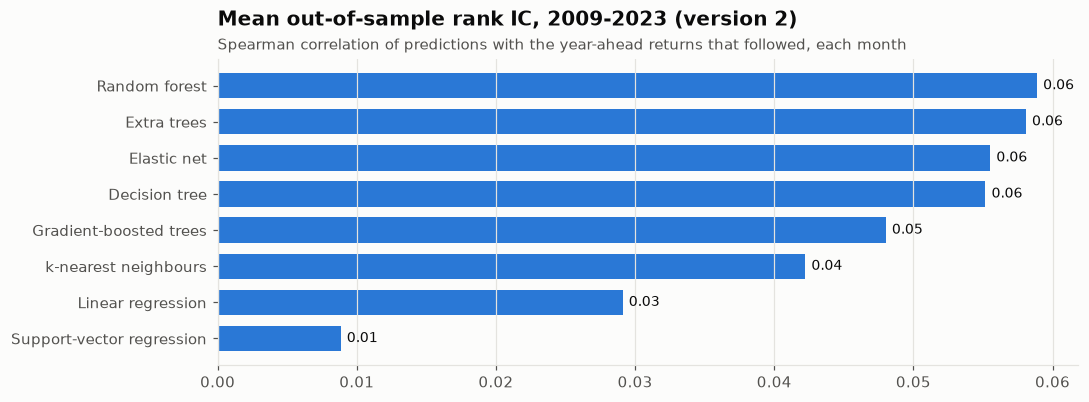

In [7]:
ic = mc.information_coefficients(predictions, returns, data.members)
summary = mc.ic_summary(ic).rename(index=LABELS).sort_values("mean_ic", ascending=False)
display(
    summary.style.format(
        {"mean_ic": "{:+.3f}", "ic_sd": "{:.3f}", "positive": "{:.0%}", "t_nw": "{:+.1f}", "months": "{:.0f}"}
    )
)
fig = charts.ranked_bars(
    summary["mean_ic"],
    "Mean out-of-sample rank IC, 2009-2023 (version 2)",
    subtitle="Spearman correlation of predictions with the year-ahead returns that followed, each month",
)

In [8]:
yearly = ic.groupby(ic.index.year).mean().rename(columns=LABELS)
print("Mean rank IC by the year of the decision date")
display(
    yearly.dropna(how="all")
    .style.format("{:+.3f}", na_rep="")
    .background_gradient(cmap="RdYlGn", vmin=-0.15, vmax=0.15, axis=None)
)

Mean rank IC by the year of the decision date


,Linear regression,Elastic net,k-nearest neighbours,Support-vector regression,Decision tree,Random forest,Extra trees,Gradient-boosted trees
2009,-0.122,-0.142,-0.066,-0.055,-0.020,-0.051,-0.085,-0.047
2010,+0.077,+0.112,+0.117,+0.016,+0.106,+0.133,+0.138,+0.119
2011,+0.037,,-0.009,-0.035,+0.033,+0.026,+0.012,-0.024
2012,-0.052,,-0.076,-0.056,+0.021,-0.021,-0.054,-0.029
2013,+0.055,,+0.051,+0.030,+0.047,+0.072,+0.069,+0.061
2014,+0.088,,+0.063,+0.020,+0.087,+0.092,+0.084,+0.091
2015,+0.052,+0.208,+0.076,+0.039,+0.061,+0.084,+0.088,+0.051
2016,+0.018,+0.010,+0.053,+0.034,+0.042,+0.072,+0.060,+0.090
2017,+0.056,+0.033,+0.049,-0.001,+0.077,+0.048,+0.044,+0.057
2018,+0.203,+0.279,+0.120,+0.056,+0.224,+0.190,+0.231,+0.172


## Step 4 - the choice, made each January from what was known

Each row is a January: each candidate's average IC over the months known that day, how many months that is, and the
model chosen for the year. The "hindsight winner" is the best over the whole period - what could not be known in
2010.

In [9]:
dates = data.rebalances[data.rebalances >= pd.Timestamp(START)]
table = mc.selection_table(ic, dates)
shown = table.rename(columns=LABELS).assign(chosen=table["chosen"].map(LABELS))
display(shown.style.format({LABELS[n]: "{:+.3f}" for n in v2.CANDIDATES}, na_rep=""))
print(f"Hindsight winner over 2009-2023: {summary.index[0]}")
print("Years each model was chosen:", shown["chosen"].value_counts().to_dict())

,Linear regression,Elastic net,k-nearest neighbours,Support-vector regression,Decision tree,Random forest,Extra trees,Gradient-boosted trees,dates,chosen
year,,,,,,,,,,
2010,,,,,,,,,0,Ensemble of all eight
2011,-0.120,-0.137,-0.061,-0.050,-0.016,-0.048,-0.081,-0.045,13,Decision tree
2012,-0.022,-0.015,+0.025,-0.019,+0.043,+0.041,+0.027,+0.036,24,Decision tree
2013,-0.022,-0.015,+0.025,-0.019,+0.043,+0.041,+0.027,+0.036,24,Decision tree
2014,-0.022,-0.015,+0.025,-0.019,+0.043,+0.041,+0.027,+0.036,24,Decision tree
2015,-0.022,-0.015,+0.025,-0.019,+0.043,+0.041,+0.027,+0.036,24,Decision tree
2016,-0.022,-0.015,+0.025,-0.019,+0.043,+0.041,+0.027,+0.036,24,Decision tree
2017,+0.001,+0.053,+0.040,-0.000,+0.046,+0.052,+0.043,+0.040,37,Elastic net
2018,+0.006,+0.047,+0.045,+0.009,+0.047,+0.059,+0.050,+0.053,48,Random forest


Hindsight winner over 2009-2023: Random forest
Years each model was chosen: {'Decision tree': 7, 'Extra trees': 3, 'Elastic net': 2, 'Random forest': 2, 'Ensemble of all eight': 1}


In [10]:
pooled = mc.ensemble(predictions, data.members)
chosen = mc.chosen_score(predictions, table["chosen"], data.members)
ic_extra = pd.DataFrame(
    {
        "walk-forward choice": mc.rank_ic(chosen, returns, data.members),
        "ensemble": mc.rank_ic(pooled, returns, data.members),
    }
)
by_year = pd.concat([ic_extra, ic.mean(axis=1).rename("average of the eight")], axis=1)
by_year = by_year[by_year.index >= pd.Timestamp(START)].groupby(lambda d: d.year).mean()
display(by_year.T.style.format("{:+.3f}", na_rep=""))
display(
    pd.DataFrame(
        {
            "mean IC 2010-2023": by_year.mean(),
            "t_nw": [mc.newey_west_t(ic_extra.loc[START:, c]) for c in ic_extra]
            + [mc.newey_west_t(ic.mean(axis=1).loc[START:])],
        }
    ).style.format({"mean IC 2010-2023": "{:+.3f}", "t_nw": "{:+.1f}"})
)

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
walk-forward choice,+0.127,+0.033,+0.021,+0.047,+0.087,+0.061,+0.042,+0.033,+0.190,+0.151,-0.308,+0.060,+0.130,+0.117,
ensemble,+0.127,+0.007,-0.047,+0.069,+0.096,+0.104,+0.060,+0.056,+0.227,+0.143,-0.222,+0.035,+0.154,+0.105,
average of the eight,+0.102,+0.006,-0.038,+0.055,+0.075,+0.082,+0.047,+0.045,+0.184,+0.113,-0.180,+0.028,+0.121,+0.084,


,mean IC 2010-2023,t_nw
walk-forward choice,+0.056,+2.1
ensemble,+0.065,+2.5
average of the eight,+0.052,+2.5


## Step 5 - deciles: where the ranking pays

Each month every score sorts the members into ten groups; the table shows each group's equal-weighted return over the
next month in excess of the average member, a year, from 2010 (before costs; Altman's distress zone ranks last). A
long-only portfolio buys from the top decile.

In [11]:
scores = {name: ml.distress_last(p, data.ratios) for name, p in predictions.items()}
scores["walk-forward choice"] = ml.distress_last(chosen, data.ratios)
scores[mc.FALLBACK] = ml.distress_last(pooled, data.ratios)
after = data.rebalances >= pd.Timestamp(START)
deciles = {LABELS.get(n, n): decile_returns(s.loc[after], data.returns, data.members) for n, s in scores.items()}
excess = pd.DataFrame({n: d["excess"] for n, d in deciles.items()}).T
excess["top t"] = [d.loc[10, "t"] for d in deciles.values()]
display(excess.style.format("{:+.1%}").format("{:+.1f}", subset=["top t"]))

decile,1,2,3,4,5,6,7,8,9,10,top t
Linear regression,-0.4%,+0.1%,+1.5%,+0.3%,+0.4%,-0.6%,-1.1%,-0.7%,+0.3%,+0.1%,+0.1
Elastic net,+0.7%,+0.9%,+1.6%,+0.3%,+0.3%,-1.1%,-1.0%,-1.5%,-0.3%,-0.3%,-0.1
k-nearest neighbours,+0.6%,+0.1%,+0.1%,-0.7%,-0.3%,+0.0%,-1.1%,+0.4%,+0.4%,+0.6%,+0.3
Support-vector regression,-0.6%,-1.7%,+1.0%,-1.6%,+1.1%,-0.4%,+0.2%,+1.8%,+0.1%,+0.0%,+0.0
Decision tree,+1.5%,-1.8%,+0.1%,-0.9%,-3.3%,+1.5%,+0.2%,+0.5%,-1.0%,-0.2%,-0.1
Random forest,+0.4%,+0.7%,+0.0%,-1.6%,+1.3%,-1.4%,-0.5%,-0.3%,+0.4%,+1.1%,+0.6
Extra trees,+1.0%,+0.6%,-0.3%,-0.8%,-0.2%,-1.0%,-0.1%,-0.5%,+0.2%,+1.0%,+0.5
Gradient-boosted trees,+0.7%,-0.8%,-0.4%,-0.1%,+0.0%,-0.1%,+0.5%,+0.4%,+0.2%,-0.4%,-0.3
walk-forward choice,-0.1%,+1.1%,-0.2%,-1.4%,-0.1%,-0.6%,+1.0%,-3.0%,+0.2%,+0.6%,+0.2
Ensemble of all eight,+0.0%,+1.4%,-1.3%,+0.4%,-0.8%,-0.4%,-0.7%,-0.1%,+0.3%,+1.2%,+0.6


## Step 6 - the portfolios, every one registered

Each score runs in 5.1's portfolio and is registered in the family `ml_model_choice_v2_lo`. The *deflated active
Sharpe ratio* is the probability that a run's information ratio beats what the luckiest of the trials would show by
chance (95 % would count as evidence): first with this family's trials, then with both studies'.

In [12]:
# the registry is the shared database: connected here, just before the runs, because a serverless database
# pauses when idle and is woken by the first connection
engine = get_engine()
base = StrategyConfig(
    family=v2.FAMILY,
    universe="SP1500",
    start=START,
    end=END,
    enter=0.30,
    exit_=0.40,
    long_only=True,
    beta_neutral=False,
    weighting="market_cap",
)
runs = {}
for name, score in scores.items():
    config = replace(base, factors=((f"ml:{name}", 1.0),))
    runs[LABELS.get(name, name)] = mc.run_score(data, config, score, protocol=v2.PROTOCOL, engine=engine)
both = trial_count(engine, mc.FAMILY) + trial_count(engine, v2.FAMILY)
sptm = vendor_returns(cache, "SPTM", total=True)
metrics = pd.DataFrame({name: r.metrics for name, r in runs.items()}).T
metrics["deflated, both studies"] = [
    deflated_active(r.backtest.net, data.benchmark, float(r.metrics["information_ratio"]), both) for r in runs.values()
]
COLUMNS = {
    "cagr": "{:.1%}",
    "vol": "{:.1%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.0%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated_active_sharpe": "{:.0%}",
    "deflated, both studies": "{:.0%}",
    "turnover": "{:.1f}",
}
display(metrics[list(COLUMNS)].sort_values("information_ratio", ascending=False).style.format(COLUMNS))
print("Registered as research runs", {name: r.run_id for name, r in runs.items()})
print("Trials in this family:", int(metrics["trials"].max()), "| in both studies:", both)

,cagr,vol,sharpe,max_drawdown,active_return,tracking_error,information_ratio,deflated_active_sharpe,"deflated, both studies",turnover
Support-vector regression,15.2%,17.9%,0.88,-34%,+1.1%,2.9%,+0.38,46%,33%,4.9
Random forest,14.1%,16.4%,0.89,-33%,+0.1%,3.0%,+0.00,6%,3%,2.4
k-nearest neighbours,14.0%,16.6%,0.87,-32%,+0.0%,3.1%,-0.03,5%,2%,1.7
Extra trees,13.9%,16.2%,0.89,-33%,-0.1%,3.0%,-0.08,3%,1%,1.3
Ensemble of all eight,13.8%,16.4%,0.87,-32%,-0.2%,2.9%,-0.10,3%,1%,1.9
Gradient-boosted trees,13.7%,16.8%,0.85,-33%,-0.3%,3.0%,-0.11,2%,1%,3.8
Decision tree,13.6%,16.9%,0.84,-32%,-0.3%,3.3%,-0.12,2%,1%,3.4
Linear regression,13.7%,16.3%,0.87,-32%,-0.3%,3.0%,-0.13,2%,1%,2.1
walk-forward choice,13.3%,16.8%,0.83,-33%,-0.6%,3.2%,-0.21,1%,0%,2.7
Elastic net,9.5%,14.3%,0.71,-33%,-4.0%,6.8%,-0.65,0%,0%,0.9


Registered as research runs {'Linear regression': 150, 'Elastic net': 151, 'k-nearest neighbours': 152, 'Support-vector regression': 153, 'Decision tree': 154, 'Random forest': 155, 'Extra trees': 156, 'Gradient-boosted trees': 157, 'walk-forward choice': 158, 'Ensemble of all eight': 159}
Trials in this family: 10 | in both studies: 20


### Version 1 against version 2, model by model

The same portfolio and the same algorithm, before and after the four changes (version 1: the newest registered run of
each score in `ml_model_choice_lo`, notebook 5.1).

In [13]:
before = score_metrics(engine, mc.FAMILY).rename(index=LABELS)
pairs = {"return a year": "cagr", "information ratio": "information_ratio", "deflated": "deflated_active_sharpe"}
side = pd.concat(
    {label: pd.DataFrame({"5.1": before[key], "5.2": metrics[key]}) for label, key in pairs.items()}, axis=1
)
side = side.loc[metrics.sort_values("information_ratio", ascending=False).index]
display(
    side.style.format("{:.1%}", subset=["return a year", "deflated"]).format("{:+.2f}", subset=["information ratio"])
)

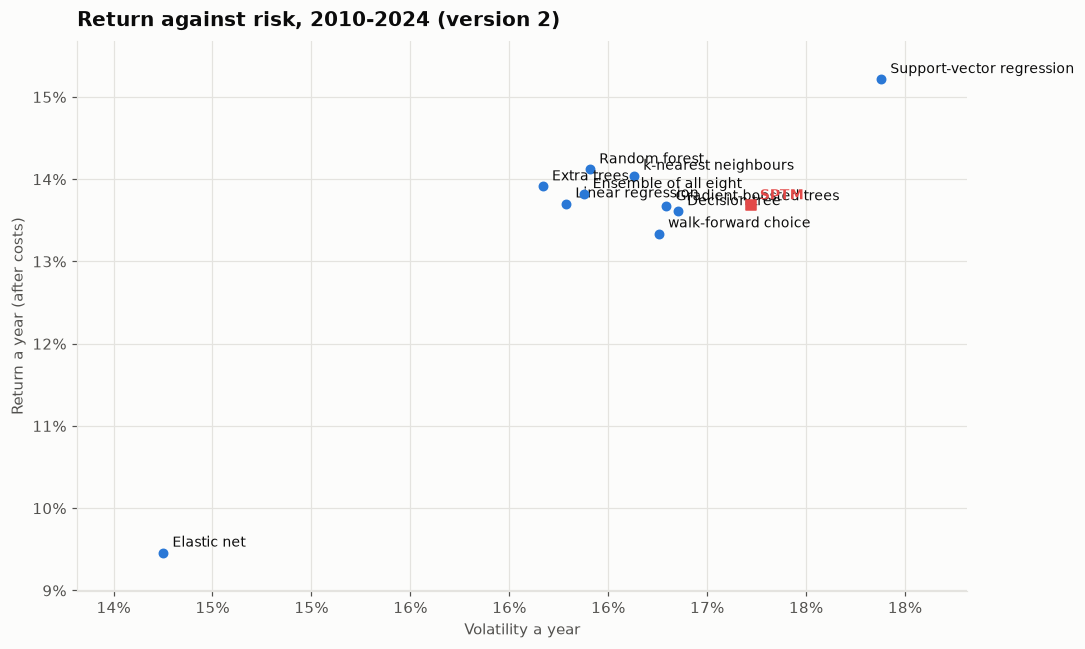

In [14]:
spread = metrics[["vol", "cagr"]].astype(float).rename(columns={"vol": "x", "cagr": "y"})
spread.loc["SPTM"] = [
    float(sptm.loc[START:END].std() * np.sqrt(252)),
    float((1 + sptm.loc[START:END]).prod() ** (252 / len(sptm.loc[START:END])) - 1),
]
fig = charts.labeled_scatter(
    spread,
    "Return against risk, 2010-2024 (version 2)",
    xlabel="Volatility a year",
    ylabel="Return a year (after costs)",
    highlight="SPTM",
)

Each year: the portfolio's return minus SPTM's


trade_date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
walk-forward choice,-4.9%,+6.4%,-2.5%,-3.4%,+0.5%,+2.9%,-3.5%,+2.0%,+1.3%,+4.6%,-0.1%,-1.2%,-4.2%,-1.2%,-6.4%
Ensemble of all eight,-4.9%,+6.7%,-3.1%,-2.8%,+0.8%,-0.4%,-0.7%,+2.9%,+2.0%,+4.5%,+3.7%,-1.3%,-1.9%,-2.1%,-6.7%
Gradient-boosted trees,-4.8%,+6.7%,-3.6%,-4.1%,+1.7%,+0.7%,+1.0%,+2.0%,+3.4%,+3.0%,+0.9%,-0.9%,-3.9%,-1.8%,-5.8%


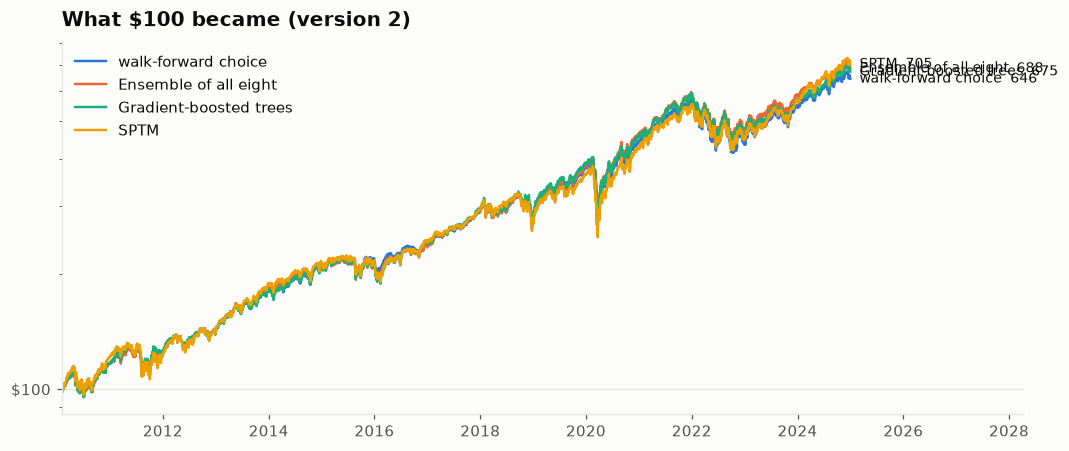

In [15]:
shown_runs = {
    k: runs[k].backtest.net for k in ("walk-forward choice", "Ensemble of all eight", "Gradient-boosted trees")
}
fig = charts.growth(shown_runs | {"SPTM": sptm}, "What $100 became (version 2)")
ahead = pd.DataFrame(
    {
        name: calendar_years({name: r, "SPTM": sptm}).pipe(lambda t, n=name: t[n] - t["SPTM"])
        for name, r in shown_runs.items()
    }
)
print("Each year: the portfolio's return minus SPTM's")
display(ahead.T.style.format("{:+.1%}", na_rep=""))

## Findings

**In short: the four changes taught the models to rank companies, but not in a way that makes money.** Version 2's
models rank S&P 1500 companies by their coming year better than chance, which version 1's could not. But the ranking
they learned is "calm, large, profitable companies usually finish higher". Those are the companies a market-value
weighted index already holds most of, and they did not earn more on average. The portfolios end where 5.1's did, next
to the market, with somewhat less risk.

**1. The repairs worked as intended (step 2).** The share of the target's variation common to the date fell from 18 %
to 0 %, and the largest target value from +8,364 % to 1. The models' predictions now vary almost only across companies
(at most 1 % common to the date, against up to 76 % in 5.1).

**2. The ranking skill is real (step 3).** Every mean rank IC over 2009-2023 is positive. The random forest is
highest at +0.059, then extra trees +0.058, the elastic net +0.056, the decision tree +0.055, gradient-boosted trees
+0.048 and k-nearest neighbours +0.042. Five of these pass a Newey-West t of 2 (2.0 to 2.6), against at most +0.003
(t 0.5) in 5.1. The pre-registered combinations hold up too: the ensemble's IC is +0.065 (t 2.5) and the walk-forward
choice's +0.056 (t 2.1). The skill is not steady, though. Decisions made in 2018 earned ICs up to +0.28, while those
made in 2020 (into the 2021 rally led by the riskiest shares) earned -0.13 to -0.31 for every model but SVR. That swing is the mark of a
*style* bet - a lasting tilt towards one kind of company - more than of company-by-company insight.

**3. What the models learned: avoid volatile shares.** A diagnosis after the run (same data, nothing refitted)
measured how closely each model's ranking follows each feature, as a rank correlation averaged over dates. Every model
ranks volatile shares low (-0.13 for SVR to -0.85 for the elastic net) and large and profitable companies high (size
+0.06 to +0.51, return on equity +0.11 to +0.54). Taken one at a time, the single features that rank best are
profitability (return on capital +0.054 to +0.057, t 2.7) and share issuance (-0.065, t -5.6: issuers lag). The
book's valuation ratios rank close to nothing (P/E +0.010, P/B +0.025).

**4. Why that ranking did not become returns.** A percentile target teaches a model the *typical* outcome, while a
portfolio earns the *average* outcome. For volatile shares the two differ sharply. The most volatile fifth of members
had a typical (median) year-ahead return 7.4 points *below* the typical member's, yet a mean return 2.2 points
*above* the average member's. The calmest fifth's mean was 2.2 points below. Most volatile shares lag, but the few that soar more than make up for them
(positive skewness). So the models were right that volatile shares usually finish lower, and the IC rewards that; a
portfolio avoiding them gives up the soaring few. The skill also fades fast at the horizon the portfolio trades:
against *next month's* returns the ICs are only +0.011 to +0.022, and the top deciles (step 5) earned between -0.4 %
and +1.2 % a year over the average member, with no t-statistic above 0.6.

**5. The portfolios: the market's return with a little less risk (step 6).** SPTM returned 13.7 % a year with 17.2 %
volatility and a worst fall of 35 %. Leaving out the elastic net (point 6), version 2's portfolios returned 13.3 % to
15.2 % with volatility of 16.2 % to 17.9 % and worst falls of 32 % to 34 %. That is less risk than 5.1's (17.9 % to
18.9 %) and than SPTM's, for about the same return - the calm, large tilt at work. Against SPTM they added nothing:
information ratios from -0.21 to +0.38, tracking errors of only 2.9 % to 3.3 %.

| | 5.1: return | 5.2: return | 5.1: information ratio | 5.2: information ratio | 5.2: deflated (10 / 20 trials) |
|---|---|---|---|---|---|
| ensemble of all eight | 13.7 % | 13.8 % | -0.01 | -0.10 | 3 % / 1 % |
| walk-forward choice | 13.2 % | 13.3 % | -0.15 | -0.21 | 1 % / 0 % |
| random forest (the hindsight winner) | 14.0 % | 14.1 % | +0.06 | +0.00 | 6 % / 3 % |
| SVR (the best portfolio) | 14.2 % | 15.2 % | +0.08 | +0.38 | 46 % / 33 % |

The best portfolio is SVR's: 15.2 % a year, information ratio +0.38. Yet SVR had the weakest ranking of the eight
(IC +0.009, t 1.0), and its predictions lean least on volatility. Its portfolio did well without its ranking
explaining why, and its deflated active Sharpe ratio is 46 % counting this family's ten trials and 33 % counting both
studies' twenty. Both are far from the 95 % that would count as evidence: this is what the luckiest of many no-skill
portfolios looks like.

**6. Two weaknesses of the protocol, reported rather than repaired.** The elastic net's cross-validation found no
penalty worth fitting on 38 month-ends from 2011 to 2014, so it predicted the same value for every company. That is a
legitimate "no signal" answer, but the protocol handles it badly in two places:

* With every company tied, none reaches the top 30 %, so its portfolio held cash for most of four rising years. That
  explains its 9.5 % a year: it is not a measure of the model.
* A forecast that ranks nobody has no IC, and the choice rule compares candidates only on months where all eight
  have one. So from 2012 to 2016 the choice rested on the same 24 months from 2009-2010, and picked the decision tree
  each year.

The registered results stand as they ran, because changing the rules after seeing them would undo the
pre-registration. A third version should state in advance that a flat forecast scores an IC of 0 and holds the
index. (The ensemble, which needs no choice, is only slightly ahead of the choice - information ratio -0.10 against
-0.21 - so the conclusion does not depend on this.)

**What this means.** Version 2 answers 5.1's question. The book's models were not hopeless: asked a better-posed
question with more information, they find a real and statistically significant ranking. But a ranking is only worth
what it earns in the portfolio that uses it. Here the target - percentiles, chosen to tame outliers - steered the
models towards typical outcomes, while the portfolio is paid in average outcomes. The lesson for a version 3, to be
pre-registered as its own family, is to make the target measure what the portfolio earns. That means the year-ahead
(or next-month) return in excess of the date's average, with the extremes trimmed rather than ranked away, judged
both by the IC and by the top-decile return. The hold-out from 2025 stays closed until one configuration is chosen.

The portfolios are research runs 150-159 in the family `ml_model_choice_v2_lo`, each deflated by the family's ten
trials. Runs 140-149 are the same ten configurations from this notebook's first execution: their deflated ratios were
computed while the family was still being registered, so they count 1 to 10 trials.


## Glossary

Terms already defined in notebook 5.1 (supervised learning, bias and variance, walk-forward validation, look-ahead
and selection bias, the deflated Sharpe ratio, the rank IC, Newey-West, the ensemble, Altman's Z'') are not repeated.

* **Percentile rank** - a value's position among a group, from 0 (lowest) to 1 (highest); it keeps the order and
  discards the distances.
* **Least squares** - fitting by minimising the sum of squared errors; squaring gives large errors (outliers) a
  disproportionate say.
* **Regularisation** - any limit on how closely a model may follow its training data (shallower trees, larger leaves,
  penalties on coefficients, smaller boosting steps), trading a little bias for much less variance.
* **Cross-validation** - estimating how a setting will do on unseen data by fitting on part of the training data and
  scoring on the rest, in turn; *blocked* when the parts are consecutive stretches of time.
* **Minimum leaf size** - the fewest training examples a tree's final group may hold.
* **Momentum / reversal** - the tendency of a share's return over the past year (excluding the last month) to
  continue, and of its last month's return to partly reverse.
* **Earnings surprise** - reported earnings less what analysts expected, scaled by the spread of past surprises.
* **Net issuance** - the change in a company's share count: issuing shares dilutes, buying back concentrates.